In [2]:
%run "../../Projects/Phase 4/splitting and baseline/splitter.py"

Train: 2400, Val: 300, Test: 300


In [5]:
import os

print(os.path.exists("students_pass_model.joblib"))
print(os.path.getsize("students_pass_model.joblib"), "bytes")

True
510195 bytes


{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}
0.6993750000000001
[0.09090909 0.36842105 0.19047619 0.4        0.47368421 0.56666667
 0.80769231 0.78378378 1.        ]
[0.15446201 0.25752483 0.34989946 0.45229417 0.54506063 0.65094666
 0.7655924  0.84904424 0.940694  ]


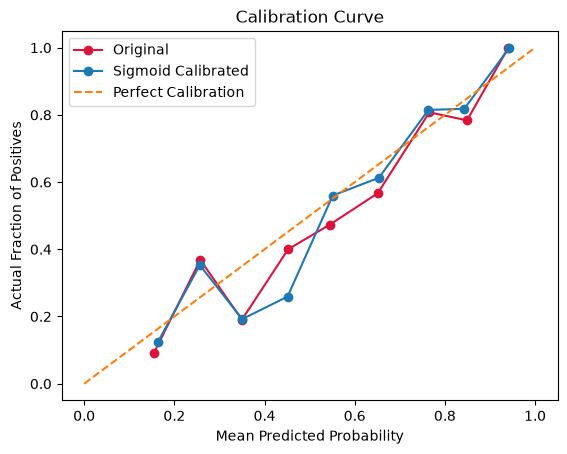

Original Brier score: 0.19557508876035726
Calibrated Brier score: 0.19148597600798511
Test Accuracy: 0.67
Test Precision: 0.6917293233082706
Test Recall: 0.7863247863247863
Test F1: 0.736
Test Brier score: 0.20883510739116506
Train: 1600
Validation: 200
Test: 200
passed
1    899
0    701
Name: count, dtype: int64
passed
1    107
0     93
Name: count, dtype: int64
passed
1    117
0     83
Name: count, dtype: int64


In [3]:
import joblib
from sklearn.metrics import (accuracy_score, precision_score, f1_score, recall_score)
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

data = pd.read_csv("../../Data/student_pass_fail.csv")

train_data, val_data, test_data = split_dataset(data)

features = ["hours_studied","attendance_pct","prev_score","sleep_hours"]

X_train = train_data[features]
y_train = train_data["passed"]
X_val = val_data[features]
y_val = val_data["passed"]
X_test = test_data[features]
y_test = test_data["passed"]

cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state = 1
)
model = GradientBoostingClassifier(random_state = 1)

param_grid = {
    "n_estimators" : [50, 100, 150],
    "learning_rate" : [0.05, 0.1, 0.2],
    "max_depth" : [2, 3, 4]
}

search = GridSearchCV(
    model,
    param_grid,
    cv=cv,
    scoring = "accuracy"
)
search.fit(X_train, y_train)
print(search.best_params_)
print(search.best_score_)

results = pd.DataFrame(search.cv_results_)
results.to_csv("grid_search_results.csv", index = False)

best_model = search.best_estimator_

calibrated_model = CalibratedClassifierCV(
    estimator=best_model,
    method = "sigmoid",
    cv = 5
)
calibrated_model.fit(X_train,y_train)
joblib.dump(calibrated_model, "students_pass_model.joblib")
calibrated_val_probabilities = calibrated_model.predict_proba(X_val)[:,1]
cal_prob_true, cal_prob_pred = calibration_curve(
    y_val,
    calibrated_val_probabilities,
    n_bins = 10
)

val_probabilities = best_model.predict_proba(X_val)[:,1]
# val_probabilities

prob_true, prob_pred = calibration_curve(
    y_val,
    val_probabilities,
    n_bins = 10
)
print(prob_true)
print(prob_pred)

plt.plot(
    prob_pred,
    prob_true,
    color="Crimson",
    marker="o",
    label="Original"
)

plt.plot(
    cal_prob_pred,
    cal_prob_true,
    marker="o",
    label="Sigmoid Calibrated"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Actual Fraction of Positives")
plt.title("Calibration Curve")

plt.legend()
plt.show()

original_brier = brier_score_loss(
    y_val,
    val_probabilities
)

calibrated_brier = brier_score_loss(
    y_val,
    calibrated_val_probabilities
)

print("Original Brier score:", original_brier)
print("Calibrated Brier score:", calibrated_brier)

test_probabilities = calibrated_model.predict_proba(X_test)[:,1]
test_predictions = (test_probabilities >= 0.5).astype(int)

test_accuracy = accuracy_score(y_test, test_predictions)
test_precision = precision_score(y_test, test_predictions)
test_recall = recall_score(y_test, test_predictions)
test_f1 = f1_score(y_test, test_predictions)
test_brier = brier_score_loss(y_test, test_probabilities)

print("Test Accuracy:", test_accuracy)
print("Test Precision:", test_precision)
print("Test Recall:", test_recall)
print("Test F1:", test_f1)
print("Test Brier score:", test_brier)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))
print(y_train.value_counts())
print(y_val.value_counts())
print(y_test.value_counts())